In [1]:
import os
import sys
from pathlib import Path

# Sube hasta la raíz del proyecto (la carpeta con requirements.txt)
raiz = Path.cwd()
for _ in range(5):
    if (raiz / 'requirements.txt').exists():
        break
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, 'src')
print('Trabajando en:', raiz)

Trabajando en: /Users/alvaroruiz/Desktop/proyecto f1/f1-strategy-analytics


# Fase 4: predicción de podios

**Pregunta:** ¿podemos predecir, *antes de la carrera*, qué pilotos acabarán en el podio?

Es un problema de **clasificación binaria**: para cada fila (un piloto en una carrera)
queremos predecir `Podio = 1` si acabó entre los 3 primeros y `0` si no.

| Día | Contenido |
|---|---|
| 21 | Ingeniería de variables |
| 22 | División temporal y data leakage |
| 23 | Regresión logística y modelo trivial |
| 24 | Random Forest y Gradient Boosting |
| 25 | Interpretación y análisis de errores |
| 26 | Guardar el modelo y exportar predicciones |

---
## Día 21 · Ingeniería de variables

Datos: resultados y clasificaciones 2018-2026 de la API de Jolpica
(`src/extract_history.py`). Solo incluyen carreras **ya disputadas**.
El código de las variables vive en `src/features.py` para poder reutilizarlo
en el pipeline y en los tests.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import features as ft

resultados = pd.read_parquet('data/raw/history_results.parquet')
quali = pd.read_parquet('data/raw/history_quali.parquet')

print(f'Resultados: {len(resultados)} filas · {resultados.groupby(["Year", "Round"]).ngroups} carreras')
print(f'Clasificación: {len(quali)} filas')
resultados.groupby('Year').agg(carreras=('Round', 'nunique'), filas=('Round', 'size'))

Resultados: 3832 filas · 190 carreras
Clasificación: 3824 filas


,carreras,filas
Year,,
2018,21,420
2019,21,420
2020,17,340
2021,22,440
2022,22,440
2023,22,440
2024,24,479
2025,24,479
2026,17,374


### Las variables

Todas se calculan en `features.construir_variables()` con una regla: **solo información
anterior a la carrera**.

| Variable | Qué mide | Cómo se evita mirar al futuro |
|---|---|---|
| `GridAdj` | Posición de salida (el pit lane, `Grid = 0`, cuenta como 20) | La parrilla se conoce antes de la salida |
| `PuntosPilotoAntes` | Puntos del piloto en la temporada | Acumulado menos los puntos de la propia carrera |
| `PuntosEquipoAntes` | Puntos del equipo en la temporada | Igual, sumando los dos pilotos |
| `MediaUlt3` | Media de la posición final en las 3 carreras previas | `shift(1)` y luego media móvil |
| `PosCircuitoPrevia` | Posición la última vez que corrió en ese circuito | `shift(1)` dentro de (piloto, circuito) |
| `DifPolePct` | % de diferencia con la pole en clasificación | La clasificación es el día anterior |

**`shift(1)` es la clave:** desplaza la columna una fila hacia abajo dentro de cada grupo,
así cada carrera ve el valor de la anterior y nunca el suyo. Si calculásemos la media de las
últimas 3 carreras *incluyendo la actual*, el modelo vería parte de la respuesta.

In [3]:
datos = ft.cargar_datos()
datos[['Year', 'Round', 'Event', 'Abbreviation', 'TeamName', 'Position', ft.TARGET] + ft.FEATURES].head(10)

,Year,Round,Event,Abbreviation,TeamName,Position,Podio,GridAdj,PuntosPilotoAntes,PuntosEquipoAntes,MediaUlt3,PosCircuitoPrevia,DifPolePct
0,2018,1,Australian Grand Prix,VET,Ferrari,1,1,3,0.0,0.0,NaN,NaN,0.830417
1,2018,1,Australian Grand Prix,HAM,Mercedes,2,1,1,0.0,0.0,NaN,NaN,0.000000
2,2018,1,Australian Grand Prix,RAI,Ferrari,3,1,2,0.0,0.0,NaN,NaN,0.818097
3,2018,1,Australian Grand Prix,RIC,Red Bull,4,0,8,0.0,0.0,NaN,NaN,1.217288
4,2018,1,Australian Grand Prix,ALO,McLaren,5,0,10,0.0,0.0,NaN,NaN,2.997634
5,2018,1,Australian Grand Prix,VER,Red Bull,6,0,4,0.0,0.0,NaN,NaN,0.880932
6,2018,1,Australian Grand Prix,HUL,Renault,7,0,7,0.0,0.0,NaN,NaN,2.917550
7,2018,1,Australian Grand Prix,BOT,Mercedes,8,0,15,0.0,0.0,NaN,NaN,1.139668
8,2018,1,Australian Grand Prix,VAN,McLaren,9,0,11,0.0,0.0,NaN,NaN,3.313045
9,2018,1,Australian Grand Prix,SAI,Renault,10,0,9,0.0,0.0,NaN,NaN,2.337243


### Un ejemplo para ver el `shift(1)` en acción

Verstappen en 2024: `PuntosPilotoAntes` en cada ronda es la suma de los puntos de las
rondas **anteriores**. En la ronda 1 vale 0 y en la ronda 2 vale lo que sacó en la 1.

In [4]:
ver = datos[(datos['Year'] == 2024) & (datos['Abbreviation'] == 'VER')]
ver[['Round', 'Event', 'Position', 'Points', 'PuntosPilotoAntes', 'MediaUlt3', 'PosCircuitoPrevia']].head(6)

,Round,Event,Position,Points,PuntosPilotoAntes,MediaUlt3,PosCircuitoPrevia
2500,1,Bahrain Grand Prix,1,26.0,0.0,1.0,1.0
2520,2,Saudi Arabian Grand Prix,1,25.0,26.0,1.0,2.0
2558,3,Australian Grand Prix,19,0.0,51.0,1.0,1.0
2559,4,Japanese Grand Prix,1,26.0,51.0,7.0,1.0
2579,5,Chinese Grand Prix,1,25.0,77.0,7.0,4.0
2600,6,Miami Grand Prix,2,18.0,102.0,7.0,1.0


Fíjate en `MediaUlt3` de la ronda 1 de 2024: usa las últimas carreras de **2023**
(la media continúa entre temporadas) y nunca la carrera de Baréin 2024 que está describiendo.
`PosCircuitoPrevia` es la posición en el mismo circuito la última vez que corrió allí.

### Prueba de que no hay fuga de información

Test empírico: **falseo el resultado de una carrera** (reordeno las posiciones y le pongo
50 puntos a todos) y recalculo las variables. Si el código es correcto, solo pueden cambiar las
variables de las carreras *posteriores*; las de esa carrera y las anteriores deben quedar idénticas.

In [5]:
r2 = resultados.copy()
mascara = (r2['Year'] == 2024) & (r2['Round'] == 10)
r2.loc[mascara, 'Position'] = r2.loc[mascara, 'Position'].sample(frac=1, random_state=0).values
r2.loc[mascara, 'Points'] = 50
alterado = ft.construir_variables(r2, quali)

clave = ['Year', 'Round', 'DriverId']
a = datos.set_index(clave)[ft.FEATURES]
b = alterado.set_index(clave)[ft.FEATURES].loc[a.index]
cambiaron = ~((a == b) | (a.isna() & b.isna())).all(axis=1)

primera = min((y, r) for y, r, _ in a.index[cambiaron.values])
print(f'Filas cuyas variables cambian: {cambiaron.sum()}')
print(f'Primera carrera afectada: año {primera[0]}, ronda {primera[1]}  (alteré la ronda 10)')
assert primera > (2024, 10), '¡Fuga de información!'

Filas cuyas variables cambian: 294
Primera carrera afectada: año 2024, ronda 11  (alteré la ronda 10)


✅ La primera carrera afectada es la 11: nada de lo anterior (ni la propia ronda 10) cambia.

### Valores perdidos

- `PosCircuitoPrevia` falta ~30 % de las veces: debutantes o circuitos nuevos (p. ej. Miami, Las Vegas).
- `MediaUlt3` falta en la primera carrera de cada piloto.
- `DifPolePct` falta cuando el piloto no marcó tiempo en clasificación.

**No los relleno aquí.** Imputar con la mediana usando *todos* los datos sería ya una forma sutil de
data leakage; lo haré dentro del `Pipeline` del modelo, ajustando el imputador solo con el entrenamiento.

In [6]:
datos[ft.FEATURES].isna().mean().mul(100).round(1).rename('% perdidos').to_frame()

,% perdidos
GridAdj,0.0
PuntosPilotoAntes,0.0
PuntosEquipoAntes,0.0
MediaUlt3,1.1
PosCircuitoPrevia,29.6
DifPolePct,1.9


### Exploración: ¿qué relación tiene cada variable con el podio?

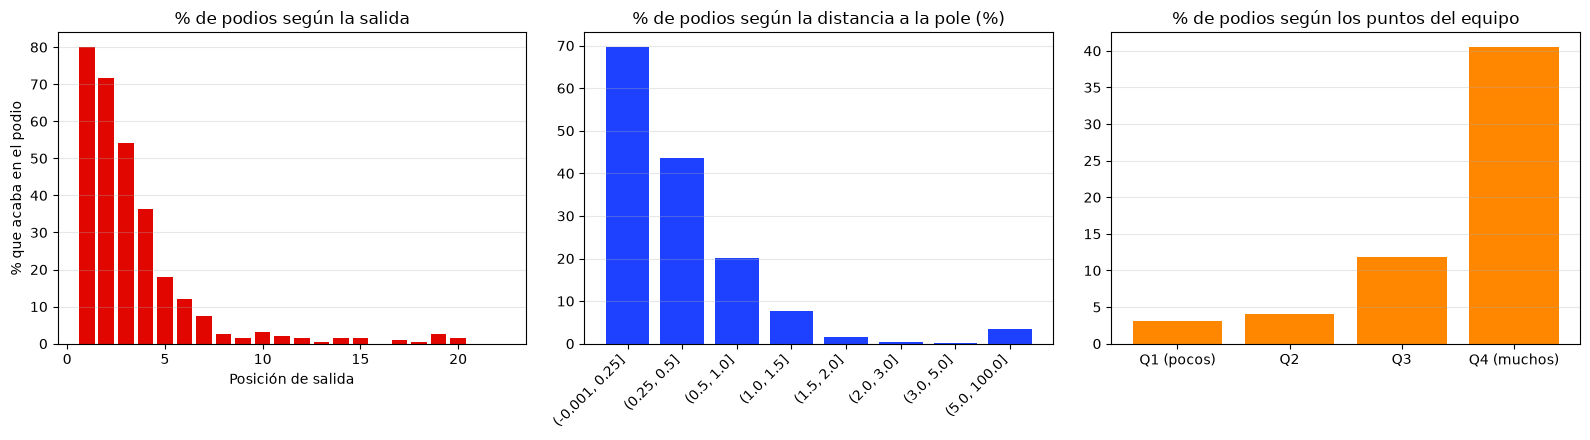

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) Tasa de podio según la posición de salida
tasa = datos.groupby('GridAdj')[ft.TARGET].mean()
axes[0].bar(tasa.index, tasa.values * 100, color='#E10600')
axes[0].set_title('% de podios según la salida')
axes[0].set_xlabel('Posición de salida')
axes[0].set_ylabel('% que acaba en el podio')

# 2) Tasa de podio según el % de diferencia con la pole (por tramos)
tramos = pd.cut(datos['DifPolePct'], [0, 0.25, 0.5, 1, 1.5, 2, 3, 5, 100], include_lowest=True)
t2 = datos.groupby(tramos, observed=True)[ft.TARGET].mean() * 100
axes[1].bar(range(len(t2)), t2.values, color='#1E41FF')
axes[1].set_xticks(range(len(t2)), [str(i) for i in t2.index], rotation=45, ha='right')
axes[1].set_title('% de podios según la distancia a la pole (%)')

# 3) Podios según puntos del equipo antes de la carrera (cuartiles)
cuartil = pd.qcut(datos['PuntosEquipoAntes'].rank(method='first'), 4, labels=['Q1 (pocos)', 'Q2', 'Q3', 'Q4 (muchos)'])
t3 = datos.groupby(cuartil, observed=True)[ft.TARGET].mean() * 100
axes[2].bar(t3.index.astype(str), t3.values, color='#FF8700')
axes[2].set_title('% de podios según los puntos del equipo')

for ax in axes:
    ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

### Conclusiones del día 21

- Solo ~15 % de las filas son podio (3 de ~20 pilotos): las clases están **desbalanceadas**, así que la
  exactitud (*accuracy*) engañará; usaremos recall, F1 y AUC.
- Salir de las 3 primeras posiciones es el factor más fuerte, pero no perfecto: de ahí que haya algo que modelar
  (estrategia, fiabilidad, salidas, safety cars...).
- La distancia a la pole y los puntos del equipo capturan **el ritmo del coche**, que la parrilla sola no recoge.
- Todas las variables pasan la prueba de invarianza: no usan información futura.

**Supuestos y limitaciones de las variables**
- `Grid = 0` se trata como 20 aunque en 2026 hay 22 coches.
- Los puntos son solo de carrera: no incluyen los puntos de las *sprints* (Jolpica los separa).
- `Position` incluye a los abandonos al final de la clasificación, así que un DNF empeora `MediaUlt3`.
- `DifPolePct` compara la mejor vuelta de cada piloto en Q1/Q2/Q3; quien cae en Q1 sale perjudicado por la evolución de la pista.
- Cambios de reglamento (2022, 2026) rompen la comparabilidad de ritmos entre temporadas.

In [8]:
datos.to_parquet('data/processed/features_podio.parquet')
print('Guardado data/processed/features_podio.parquet')

Guardado data/processed/features_podio.parquet
